# Machine Learning Homework 2026
## Section 3 - Feature Selection: 90-Day Repeat Purchase Prediction

## 3.1. Introduction

**Goal of this section.** After Section 2, every purchase is described by **173 prepared columns** (numbers, missing-value flags and one 0/1 column per category). Not all of them are useful: some carry no information about the target and some repeat the same information. Feature selection keeps the useful columns and removes the rest, **without making the predictions worse**.

**Methods compared (all covered in class):**

| Family | Idea | Methods used |
|---|---|---|
| **Filter** | Score each column with a statistic, without a model | `VarianceThreshold`, `SelectKBest` (ANOVA F-test), relevance of the original variables (point-biserial r / Cramér's V) and TypedFilter, correlation (redundancy) filter |
| **Wrapper** | Use a fitted model to remove columns step by step | `RFE` with Logistic Regression |
| **Embedded** | The model selects columns while it learns | `SelectFromModel` with L1 Logistic Regression and with a Decision Tree |
| **Combinations** | Use several families together | Sequence and vote (as in class) |

**How we judge them (method from class).** Every method is tested in the same way: a Logistic Regression is trained only with the columns that the method keeps, and its **F1 on validation data** is compared with the F1 of the same model using **all columns** (the *reference*). Because several methods reach a similar F1, the final choice also uses the **stability** of the selected columns and whether they rely on **rare categories** (3.9.2).

**Structure of this notebook:**
- 3.2 Setup and data
- 3.3 Preprocessing from Section 2
- 3.4 How we compare feature sets (time-based splits and the reference)
- 3.5 Filter methods I: VarianceThreshold, SelectKBest and relevance of the original variables
- 3.6 Filter methods II: correlation and redundancy
- 3.7 Wrapper method: RFE
- 3.8 Embedded methods: L1 and Decision Tree
- 3.9 Combining strategies, comparison of all methods and final choice
- 3.10 Testing identifier-like fields
- 3.11 Final feature set
- 3.12 Conclusion

## 3.2. Setup and data

We import the libraries, load the data and separate the target from the predictors.

- `ID` is used as the **index** (row label), exactly as in Section 2, so it is never treated as a feature and predictions can later be matched to each purchase.
- `test.csv` is loaded only to keep the same setup as the other sections. **It is not used anywhere in this section**: no selection step learns from it.

In [64]:
# ---------------------------------------------------------------
# Libraries
# ---------------------------------------------------------------
import warnings
from collections import Counter          # counts how often a column is kept across splits

import numpy as np                       # arrays and maths
import pandas as pd                      # tables (DataFrames)
import matplotlib.pyplot as plt          # plots
import seaborn as sns                    # heatmaps
from IPython.display import display      # nicer table display

# Preprocessing tools (used by the Section 2 functions)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Model and metric used to judge every feature set
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# Feature-selection methods compared in this section
from sklearn.feature_selection import (
    VarianceThreshold,   # filter: removes constant columns
    SelectKBest,         # filter: keeps the k best-scored columns
    f_classif,           # the score used by SelectKBest (ANOVA F-test)
    RFE,                 # wrapper: recursive feature elimination
    SelectFromModel,     # embedded: keeps columns a fitted model finds important
)
from sklearn.tree import DecisionTreeClassifier

# Hide warnings about constant columns (they are expected, see 3.5)
warnings.filterwarnings("ignore")

# Same random seed in every section, so results can be reproduced
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [65]:
# ---------------------------------------------------------------
# Load the data
# ---------------------------------------------------------------
# index_col="ID": ID becomes the row label, not a column (same as Section 2)
train = pd.read_csv("../data/train.csv", index_col="ID")
test = pd.read_csv("../data/test.csv", index_col="ID")   # NOT used in this section

# ---------------------------------------------------------------
# Separate the target (what we predict) from the predictors
# ---------------------------------------------------------------
target = "repeat_purchase_90d"
X = train.drop(columns=target)        # predictors
y = train[target].astype(int)         # target: 1 = buys again within 90 days, 0 = does not

print("Rows and columns of X:", X.shape)   # expected: (6534, 37)
print("Size of y:", y.shape)               # expected: (6534,)

Rows and columns of X: (6534, 37)
Size of y: (6534,)


`X` has **6,534 purchases and 37 columns** (38 columns in the file minus the target; `ID` is the index).

**Identifier-like columns.** Three columns are not normal predictors:
- `customer_id` identifies the customer. Its numeric value has no meaning (customer 500000 is not "more" than customer 100000).
- `purchase_date` is anonymised. We use it **only to split the data by time** (3.4), not as a feature.
- `random_noise` is an extra field whose meaning is unknown.

Section 2 already removes these three columns inside its preprocessing. Instead of accepting this blindly, **we test it in 3.10** by adding `customer_id` and `random_noise` back and checking whether the model improves.

## 3.3. Preprocessing from Section 2

Feature selection must be done on **the same prepared data the model will use**. Otherwise we could remove a column only because it still contains errors, or we could never select the new columns created in Section 2.

We use the same cleaning, features and transformations as Section 2. Here they are wrapped in a `Pipeline` so preprocessing is fitted again inside each split. The steps are:
1. replace invalid values (negative amounts, the 1,000,000,000 values in `spend_365d` and `prior_mean_purchase_value`, infinite values) with missing values;
2. add a `_missing` flag (0/1) for every numeric column, plus `first_purchase`, `history_unknown` and `net_value_per_detail`;
3. remove `customer_id`, `purchase_date` and `random_noise`;
4. apply `log1p` to amounts, counts and durations;
5. fill numeric gaps with the **training median** and scale the numbers;
6. fill missing categories with `__MISSING__` and one-hot encode them (one 0/1 column per category).

The steps that learn something (median, scaling, list of categories) are fitted **only on training rows**, every time the preprocessor is fitted.

In [66]:
# ---------------------------------------------------------------
# Section 2 preprocessing 
# ---------------------------------------------------------------

# Column groups
categorical_columns = [
    "payment_type", "salesperson", "commercial_zone",
    "transport_method", "warehouse", "document_series",
]
numeric_columns = X.select_dtypes(include="number").columns.tolist()
numeric_columns.remove("customer_id")     # identifier, not a measurement
numeric_columns.remove("random_noise")    # tested separately in 3.10


def clean_values(data):
    """Replace invalid numeric values with missing values (rows are kept)."""
    cleaned = data.copy()
    for column in numeric_columns:
        cleaned[column] = cleaned[column].replace([np.inf, -np.inf], np.nan)  # infinite -> missing
        cleaned.loc[cleaned[column] < 0, column] = np.nan                    # negative -> missing
    for column in ["prior_mean_purchase_value", "spend_365d"]:
        cleaned.loc[cleaned[column] >= 1_000_000_000, column] = np.nan       # 1e9 errors -> missing
    return cleaned


def add_features(data):
    """Clean the data and create the new Section 2 features."""
    prepared = clean_values(data)

    # 0/1 flag: was this value missing (or invalid) originally?
    for column in numeric_columns:
        prepared[column + "_missing"] = prepared[column].isna().astype(int)

    # First purchase (0 previous purchases) vs unknown purchase history
    prepared["first_purchase"] = (prepared["prior_purchase_count"] == 0).astype(int)
    prepared["history_unknown"] = prepared["prior_purchase_count"].isna().astype(int)

    # Net value per purchase detail (only divide by a positive count)
    detail_count = prepared["N_ Detalhes"].where(prepared["N_ Detalhes"] > 0)
    prepared["net_value_per_detail"] = prepared["Total Liquido"] / detail_count

    # Remove accidental spaces in category labels
    for column in categorical_columns:
        labels = prepared[column].astype("string").str.strip()
        labels = labels.replace("", pd.NA)
        prepared[column] = labels.to_numpy(dtype=object, na_value=np.nan)

    # Identifier-like columns are not model inputs
    prepared = prepared.drop(columns=["customer_id", "purchase_date", "random_noise"])
    return prepared


# Amounts, counts and durations that receive log1p
log_columns = numeric_columns + ["net_value_per_detail"]


def prepare_features(data):
    """Add the features and apply log1p (log of 1 + value) to large values."""
    prepared = add_features(data)
    for column in log_columns:
        prepared[column] = np.log1p(prepared[column])
    return prepared


# Names of all numeric model columns (original numbers + flags + new features)
model_numeric_columns = prepare_features(X).select_dtypes(include="number").columns.tolist()


def build_preprocessor(scale=True):
    """Return a NEW, unfitted preprocessing pipeline."""
    # Route 1: numeric columns -> fill with the training median -> scale
    numeric_steps = [("fill_missing", SimpleImputer(strategy="median", keep_empty_features=True))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)

    # Route 2: categorical columns -> fill with "__MISSING__" -> one-hot (0/1 columns)
    categorical_pipeline = Pipeline([
        ("fill_missing", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    # Apply each route to its columns and put the results side by side
    combine_columns = ColumnTransformer([
        ("numeric", numeric_pipeline, model_numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])

    # Full pipeline: create features first, then the two routes
    return Pipeline([
        ("prepare_features", FunctionTransformer(prepare_features)),
        ("combine_columns", combine_columns),
    ])

In [67]:
# ---------------------------------------------------------------
# Check that the preprocessing works
# (fitted on all training rows only for this check)
# ---------------------------------------------------------------
check_preprocessor = build_preprocessor()
X_check = check_preprocessor.fit_transform(X)

print("Columns before preparation:", X.shape[1])          # 37
print("Columns after preparation:", X_check.shape[1])     # 173
print("Any missing values left?", np.isnan(X_check).any())  # False

Columns before preparation: 37
Columns after preparation: 173
Any missing values left? False


The preprocessing turns **37 raw columns into 173 prepared columns** with no missing values. The increase comes from the `_missing` flags and from one-hot encoding (every category becomes its own 0/1 column).

**These 173 columns are the candidates for feature selection.** In names such as `numeric__spend_90d` or `categorical__payment_type_...`, the prefix shows which route of the preprocessing produced the column.

## 3.4. How we compare feature sets

### 3.4.1. Time-based splits

As in Section 2, we split the training data **by date**: the model learns from older purchases and is checked on later ones. This is the realistic situation, because `test.csv` contains purchases that happen **after** the training period.

A single split could be lucky or unlucky, so (as the professor did with repeated splits) we build **5 time-based splits**:
- **validation** = the next 10% of purchases in time, starting at 50%, 60%, 70%, 80% and 90% of the dated purchases;
- **training** = all purchases more than **90 days before** validation starts. The 90-day gap is needed because the target of a purchase is only known 90 days later; without it, training targets would "see" the validation period.

The 65 rows without a date cannot be placed in time, so they are not used in these splits (they are still used in 3.11).

In [68]:
# ---------------------------------------------------------------
# Build 5 time-based train/validation splits
# ---------------------------------------------------------------
purchase_dates = pd.to_datetime(X["purchase_date"], errors="coerce")  # text -> date (missing stays NaT)
sorted_dates = purchase_dates.dropna().sort_values()                  # dated purchases, oldest first
gap = pd.Timedelta(days=90)                                           # gap between training and validation

splits = []   # each element: (positions of training rows, positions of validation rows)
for start in [0.50, 0.60, 0.70, 0.80, 0.90]:
    # Validation starts after `start` (e.g. 50%) of the purchases in time...
    validation_start = sorted_dates.iloc[int(len(sorted_dates) * start)]
    # ...and covers the next 10% (the last split goes until the end)
    if start < 0.90:
        validation_end = sorted_dates.iloc[int(len(sorted_dates) * (start + 0.10))]
    else:
        validation_end = sorted_dates.max() + pd.Timedelta(days=1)

    # Training = purchases more than 90 days before validation starts
    train_rows = np.flatnonzero(purchase_dates < validation_start - gap)
    validation_rows = np.flatnonzero((purchase_dates >= validation_start)
                                     & (purchase_dates < validation_end))
    splits.append((train_rows, validation_rows))

    print(f"Split {len(splits)}: train {len(train_rows)} rows, "
          f"validation {len(validation_rows)} rows, starting {validation_start.date()}")

Split 1: train 3109 rows, validation 647 rows, starting 2020-10-03
Split 2: train 3709 rows, validation 646 rows, starting 2021-07-31
Split 3: train 4424 rows, validation 644 rows, starting 2022-07-13
Split 4: train 5024 rows, validation 633 rows, starting 2023-06-17
Split 5: train 5632 rows, validation 665 rows, starting 2024-03-23


Each split trains on 3,109 to 5,632 older purchases and validates on about 650 later purchases. Validation periods start between October 2020 and March 2024, so every method is tested on five different periods.

### 3.4.2. The scoring function

`heldout_f1` gives the "score" of a feature-selection method. For **each of the 5 splits** it:
1. fits the Section 2 preprocessing on the training rows only and applies it to the validation rows;
2. fits the selection method on the training rows only, and keeps the columns it chooses;
3. trains a Logistic Regression with those columns and computes the **F1** on the validation rows.

**Why F1?** F1 combines *precision* (of the customers we predict will come back, how many really do) and *recall* (of the customers who really come back, how many we find). It goes from 0 to 1, higher is better. It is the metric used in class.

Because the selection is fitted inside each split, the validation rows never help choose the columns. Choosing columns with the validation outcomes and then scoring on them would be **data leakage**.

In [69]:
def heldout_f1(select=None):
    """Return one row per split with: the number of columns used (n),
    the validation F1, and the list of columns kept.

    `select` is a function that creates a NEW selection method.
    If select=None, the model uses all columns (the reference)."""
    rows = []
    for train_rows, validation_rows in splits:
        # Training and validation rows of this split
        X_tr, X_va = X.iloc[train_rows], X.iloc[validation_rows]
        y_tr, y_va = y.iloc[train_rows], y.iloc[validation_rows]

        # 1. Prepare the data (Section 2), learning ONLY from the training rows
        preprocessor = build_preprocessor()
        A_tr = preprocessor.fit_transform(X_tr)    # fit + transform on training
        A_va = preprocessor.transform(X_va)        # only transform on validation
        names = preprocessor.named_steps["combine_columns"].get_feature_names_out()

        # 2. Choose columns (only if a selection method was given)
        keep = np.ones(len(names), dtype=bool)     # start by keeping every column
        if select is not None:
            selector = select()                    # a fresh, unfitted method
            selector.fit(A_tr, y_tr)               # learns ONLY from training rows
            keep = selector.get_support()          # True = column kept

        # 3. Train the model with the kept columns and score it on validation
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(A_tr[:, keep], y_tr)
        rows.append({
            "n": int(keep.sum()),                                   # number of columns used
            "F1": f1_score(y_va, model.predict(A_va[:, keep])),     # validation F1
            "kept": list(names[keep]),                              # which columns
        })
    return pd.DataFrame(rows)

### 3.4.3. Comparing two methods

`paired_delta` compares a method with the reference **split by split**:
- **dF1**: mean difference in F1 (positive = the method is better);
- **SEM**: standard error of that mean, i.e. how much the difference varies between splits;
- **wins**: in how many of the 5 splits the method is better;
- **verdict**: `better` or `worse` when the difference is larger than 2 × SEM, otherwise `inside the noise` (too small to be a real difference).

In [70]:
def paired_delta(scores, reference):
    """Compare two sets of F1 scores split by split (method from class)."""
    delta = np.asarray(scores) - np.asarray(reference)       # difference in each split
    sem = delta.std(ddof=1) / np.sqrt(len(delta))            # standard error of the mean difference

    # A difference smaller than 2 standard errors is treated as noise
    if not delta.any():
        verdict = "identical on every split"
    elif abs(delta.mean()) <= 2 * sem:
        verdict = "inside the noise"
    elif delta.mean() > 0:
        verdict = "better"
    else:
        verdict = "worse"

    return {"dF1": round(delta.mean(), 4), "SEM": round(sem, 4),
            "wins": f"{int((delta > 0).sum())}/{len(delta)}", "verdict": verdict}

### 3.4.4. The results table and the reference

`report` stores the result of each method in one table (`results`) so all methods can be compared side by side, and it prints the columns the method kept in most of the 5 splits. Because the selection is refitted in every split, the kept columns can change slightly from split to split. A column kept in 5/5 splits is a more stable choice than one kept in 3/5.

The first row is the **reference: all features**, with no selection.

In [71]:
results = {}   # one row per method: number of columns, F1 and comparison with the reference


def report(name, run):
    """Save one method's result in the table and show which columns it kept."""
    row = {"columns": round(run["n"].mean(), 1), "F1": round(run["F1"].mean(), 4)}
    if name != "all features":
        row.update(paired_delta(run["F1"], reference["F1"]))   # compare with the reference
    results[name] = row
    print(name, "->", row)

    # Columns kept in more than half of the 5 splits, with how often they were kept
    counts = Counter(col for cols in run["kept"] for col in cols)
    common = [f"{col} ({n}/{len(splits)})"
              for col, n in counts.most_common() if n > len(splits) / 2]
    if len(common) <= 30:   # do not print very long lists
        print("Kept in most splits:", ", ".join(common))


# The reference: all columns, no selection
reference = heldout_f1()
display(reference[["n", "F1"]].round(4))
print(f"Mean F1 with all features: {reference['F1'].mean():.4f}")
report("all features", reference)

,n,F1
0,142,0.7077
1,147,0.7534
2,157,0.6746
3,164,0.7696
4,169,0.7548


Mean F1 with all features: 0.7320
all features -> {'columns': np.float64(155.8), 'F1': np.float64(0.732)}


**Reference:** with all columns, the Logistic Regression reaches a mean validation **F1 of about 0.732**. The model uses 142 to 169 columns depending on the split (about 156 on average), not 173, because some categories do not yet exist in the older training periods.

Every method below is compared with this reference.

## 3.5. Filter methods I: VarianceThreshold, SelectKBest and relevance of the original variables

Filter methods score each column with a statistic, without training a predictive model.

### 3.5.1. VarianceThreshold

`VarianceThreshold(threshold=0)` removes columns whose **variance is zero**, i.e. columns that have the same value in every training row. A constant column cannot help the model distinguish customers. This method does **not** look at the target.

In [72]:
# Remove constant columns (variance = 0), fitted on the training rows of each split
variance_run = heldout_f1(select=lambda: VarianceThreshold(threshold=0))
report("VarianceThreshold(0)", variance_run)

VarianceThreshold(0) -> {'columns': np.float64(134.8), 'F1': np.float64(0.7318), 'dF1': np.float64(-0.0002), 'SEM': np.float64(0.0002), 'wins': '0/5', 'verdict': 'inside the noise'}


**Results:** on average the model goes from about **156 to about 135 columns**, and the F1 stays practically the same as with all features.

The removed columns are mostly `_missing` flags created in Section 2. They are constant inside the time splits: the 65 rows with almost no information are also the rows without a purchase date, so they never enter a time split and those flags are always 0 there.

VarianceThreshold only detects constant columns. It does not tell us which columns are related to the target, so we need other methods.

### 3.5.2. SelectKBest

`SelectKBest` gives each column a score that measures its relationship with the target and keeps the **k best** columns.

We use the **ANOVA F-test** (`f_classif`). It checks whether the mean of a column is different for customers who come back (target = 1) and customers who do not (target = 0). For a 0/1 target, it ranks columns in the same order as the point-biserial correlation (for numeric columns) and the phi / Cramér's V coefficient (for the 0/1 category columns) used in class. So one score can rank numeric and category columns together.

As in class, we try a narrow budget (**k = 10**) and a wider one (**k = 25**).

In [73]:
# Keep the 10 and the 25 columns with the highest ANOVA F score
kbest10_run = heldout_f1(select=lambda: SelectKBest(f_classif, k=10))
report("SelectKBest(k=10)", kbest10_run)

kbest25_run = heldout_f1(select=lambda: SelectKBest(f_classif, k=25))
report("SelectKBest(k=25)", kbest25_run)

display(pd.DataFrame(results).T)

SelectKBest(k=10) -> {'columns': np.float64(10.0), 'F1': np.float64(0.7403), 'dF1': np.float64(0.0083), 'SEM': np.float64(0.0066), 'wins': '4/5', 'verdict': 'inside the noise'}
Kept in most splits: numeric__days_since_previous_purchase (5/5), numeric__prior_purchase_count (5/5), numeric__prior_mean_gap_days (5/5), numeric__purchase_count_90d (5/5), numeric__spend_90d (5/5), numeric__purchase_count_180d (5/5), numeric__spend_180d (5/5), numeric__purchase_count_365d (5/5), numeric__spend_365d (5/5), numeric__purchase_count_30d (4/5)
SelectKBest(k=25) -> {'columns': np.float64(25.0), 'F1': np.float64(0.7533), 'dF1': np.float64(0.0213), 'SEM': np.float64(0.0123), 'wins': '3/5', 'verdict': 'inside the noise'}
Kept in most splits: numeric__Total Desc_ Linha (5/5), numeric__days_since_previous_purchase (5/5), numeric__prior_purchase_count (5/5), numeric__prior_total_spend (5/5), numeric__prior_min_purchase_value (5/5), numeric__prior_max_purchase_value (5/5), numeric__prior_mean_gap_days (5/5

,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise


**Results:** with only 10 columns the F1 is about **0.740**, and with 25 columns about **0.753**, against 0.732 with all features. Both differences are *inside the noise*: keeping far fewer columns does not hurt the model.

- The **top 10** are all about **past purchase behaviour**: recency (`days_since_previous_purchase`), number of previous purchases, time between purchases, and purchase counts and spend over 30, 90, 180 and 365 days.
- With **k = 25**, some missing-value flags, `first_purchase` and a few categories (one payment type, two salespeople, one transport method) also enter.
- With the Section 2 cleaning, `spend_365d` enters the top 10. In a first attempt on the raw data, it scored almost zero because of the 1,000,000,000 values. This shows why selection must use the cleaned data.

**Limitation:** SelectKBest scores each column **alone**, so it cannot see that several of its top columns repeat the same information. We check this next.

### 3.5.3. Relevance of the original variables

SelectKBest scores each prepared column separately: one 0/1 column per category. As in class, we also ask whether each **original variable as a whole** is related to the target, using the index its type allows:

- for a **numeric** variable, the absolute **point-biserial correlation** |r| with the 0/1 target;
- for a **categorical** variable, a **chi-square test of independence** and **Cramér's V**. Unlike the chi-square statistic, V does not depend on the number of rows or categories, and it goes from 0 to 1 like |r|, so both can be ranked together.

The chi-square p-value is only reliable when every **expected count** in the table is at least about 5, so we also report the smallest expected count.

We compute these scores on the training rows of the first time split, after the Section 2 cleaning.

In [74]:
# ---------------------------------------------------------------
# Relevance of each ORIGINAL variable (method from class)
# ---------------------------------------------------------------
from scipy.stats import chi2_contingency, pointbiserialr


def cramers_v(column, outcome):
    """Chi-square test between a categorical variable and the target.
    Returns Cramer's V (0 = no relation, 1 = perfect relation), the p-value,
    and the smallest expected count (the p-value is only reliable if it is >= 5)."""
    table = pd.crosstab(column, outcome)
    if min(table.shape) < 2:                      # only one category: no relation to measure
        return 0.0, np.nan, np.nan
    statistic, p, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return v, p, expected.min()


def typed_relevance(rows, outcome):
    """One score per ORIGINAL variable, each with the index its type allows:
    |point-biserial r| for numeric variables, Cramer's V for categorical ones.
    Both go from 0 to 1, so they can be ranked together."""
    prepared = prepare_features(rows)             # Section 2 cleaning, new features and log1p
    scores = {}
    for column in model_numeric_columns:
        values = prepared[column].fillna(prepared[column].median()).to_numpy(dtype=float)
        if values.std() == 0:                     # constant column: no relation
            scores[column] = 0.0
        else:
            scores[column] = abs(pointbiserialr(outcome.to_numpy(dtype=int), values).statistic)
    for column in categorical_columns:
        labels = prepared[column].fillna("__MISSING__").astype(str)
        scores[column] = cramers_v(labels, outcome)[0]
    return pd.Series(scores).sort_values(ascending=False)

In [75]:
# Relevance on the training rows of the first time split
first_train_rows, _ = splits[0]
source_scores = typed_relevance(X.iloc[first_train_rows], y.iloc[first_train_rows])

# Details of the chi-square test for each categorical variable
first_prepared = prepare_features(X.iloc[first_train_rows])
categorical_table = []
for column in categorical_columns:
    labels = first_prepared[column].fillna("__MISSING__").astype(str)
    v, p, min_expected = cramers_v(labels, y.iloc[first_train_rows])
    categorical_table.append({
        "variable": column,
        "categories": labels.nunique(),
        "Cramer's V": round(v, 3),
        "p-value": f"{p:.2g}",
        "smallest expected count": round(min_expected, 2),
        "rank among all variables": list(source_scores.index).index(column) + 1,
    })

print("Top 15 original variables by relevance:")
display(source_scores.head(15).round(3).to_frame("relevance"))
print("Categorical variables:")
display(pd.DataFrame(categorical_table))

Top 15 original variables by relevance:


,relevance
purchase_count_90d,0.393
purchase_count_180d,0.384
purchase_count_365d,0.382
spend_90d,0.358
prior_mean_gap_days,0.315
prior_purchase_count,0.313
spend_180d,0.312
transport_method,0.311
days_since_previous_purchase,0.280
spend_365d,0.279


Categorical variables:


,variable,categories,Cramer's V,p-value,smallest expected count,rank among all variables
0,payment_type,6,0.204,2.4e-26,0.89,17
1,salesperson,7,0.178,6.1e-19,1.34,20
2,commercial_zone,2,0.025,0.17,8.95,40
3,transport_method,63,0.311,6.3e-33,0.45,8
4,warehouse,3,0.048,0.028,9.40,38
5,document_series,2,0.000,0.99,598.19,44


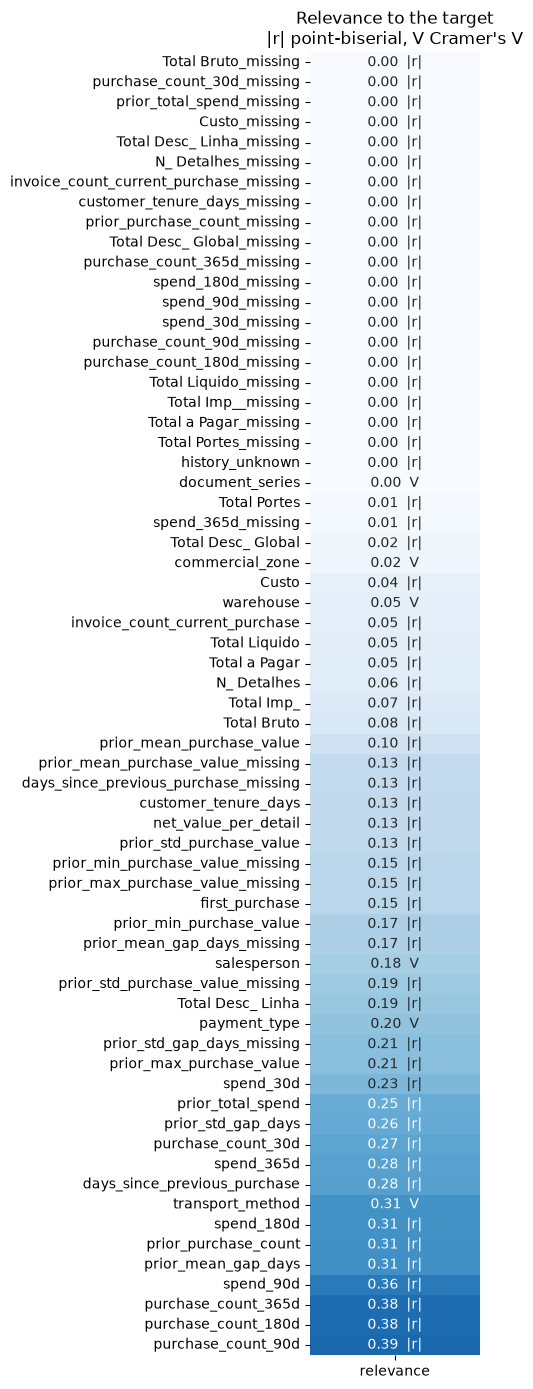

In [76]:
# Heatmap of the relevance of every original variable (as in class)
relevance_view = source_scores.sort_values().to_frame("relevance")
labels = [[f"{value:.2f}  {'V' if name in categorical_columns else '|r|'}"]
          for name, value in relevance_view["relevance"].items()]

fig, ax = plt.subplots(figsize=(5, 14))
sns.heatmap(relevance_view, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=0.5, cbar=False, ax=ax)
ax.set(title="Relevance to the target\n|r| point-biserial, V Cramer's V", xlabel="", ylabel="")
fig.tight_layout()
plt.show()

**Results:**
- The most relevant variables are about **recent purchase behaviour**: purchase counts over 90, 180 and 365 days (|r| ≈ 0.38–0.39), spend over 90 days, the time between purchases and the number of previous purchases.
- Among the categorical variables, **`transport_method` is the strongest** (V ≈ 0.31, 8th of all variables), followed by `payment_type` (V ≈ 0.20) and `salesperson` (V ≈ 0.18). `commercial_zone`, `warehouse` and `document_series` are almost unrelated to the target (V ≤ 0.05).
- **Caveat:** for `transport_method`, `payment_type` and `salesperson`, the smallest expected count is **below 5** (0.45 for transport, which has 62 categories in this split). Some categories are used by very few purchases, so their p-values should not be read, and their V can be inflated by those small categories. 

We come back to this problem in 3.9.2.

#### TypedFilter: keeping whole variables

The TypedFilter from class keeps the **k most relevant original variables**. A categorical variable keeps or loses **all its 0/1 columns together**. As in class, we keep 8 variables; we also try 15. The ranking is computed again on the training rows of each split.

In [77]:
def source_of(name):
    """Original variable of a prepared column:
    numeric__spend_90d -> spend_90d ; categorical__payment_type_X -> payment_type"""
    for column in categorical_columns:
        if name.startswith(f"categorical__{column}_"):
            return column
    return name.replace("numeric__", "")


def heldout_f1_typed(k):
    """TypedFilter from class: keep the k ORIGINAL variables with the highest relevance.
    A categorical variable keeps or loses ALL its 0/1 columns together.
    The ranking is computed on the training rows of each split only."""
    rows = []
    for train_rows, validation_rows in splits:
        X_tr, X_va = X.iloc[train_rows], X.iloc[validation_rows]
        y_tr, y_va = y.iloc[train_rows], y.iloc[validation_rows]

        # Section 2 preprocessing, fitted on training rows only
        preprocessor = build_preprocessor()
        A_tr = preprocessor.fit_transform(X_tr)
        A_va = preprocessor.transform(X_va)
        names = preprocessor.named_steps["combine_columns"].get_feature_names_out()

        # The k most relevant original variables (training rows only)
        best = set(typed_relevance(X_tr, y_tr).head(k).index)
        keep = np.array([source_of(name) in best for name in names])

        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(A_tr[:, keep], y_tr)
        rows.append({"n": int(keep.sum()),
                     "F1": f1_score(y_va, model.predict(A_va[:, keep])),
                     "kept": list(names[keep])})
    return pd.DataFrame(rows)


typed8_run = heldout_f1_typed(8)
report("TypedFilter (8 variables)", typed8_run)

typed15_run = heldout_f1_typed(15)
report("TypedFilter (15 variables)", typed15_run)

# Which original variables were kept with k = 8, and in how many splits?
kept_variables = Counter(v for cols in typed8_run["kept"] for v in {source_of(c) for c in cols})
print("\nVariables kept with k = 8 (number of splits):", dict(kept_variables))
display(pd.DataFrame(results).T)

TypedFilter (8 variables) -> {'columns': np.float64(78.4), 'F1': np.float64(0.738), 'dF1': np.float64(0.006), 'SEM': np.float64(0.0068), 'wins': '4/5', 'verdict': 'inside the noise'}
TypedFilter (15 variables) -> {'columns': np.float64(90.6), 'F1': np.float64(0.7348), 'dF1': np.float64(0.0028), 'SEM': np.float64(0.0072), 'wins': '3/5', 'verdict': 'inside the noise'}

Variables kept with k = 8 (number of splits): {'spend_180d': 5, 'prior_mean_gap_days': 5, 'prior_purchase_count': 5, 'spend_90d': 5, 'purchase_count_365d': 5, 'transport_method': 5, 'purchase_count_180d': 5, 'purchase_count_90d': 5}


,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise
TypedFilter (8 variables),78.4,0.738,0.006,0.0068,4/5,inside the noise
TypedFilter (15 variables),90.6,0.7348,0.0028,0.0072,3/5,inside the noise


**Results:** with 8 variables the F1 is about **0.738**, and with 15 variables about **0.735**, both *inside the noise* compared with all features.

With k = 8, the filter keeps seven purchase-history variables and **`transport_method`** in every split. Although it keeps only 8 variables, the model uses about **78 columns**, because `transport_method` alone brings about 60 one-hot columns. Scoring whole variables is useful to see which variables matter, but here it shows that one variable with many rare categories can take most of the columns.

## 3.6. Filter methods II: correlation and redundancy

Correlation has two different uses in feature selection (as explained in class):
- **Relevance:** is a column related to the target? (SelectKBest answers this.)
- **Redundancy:** do two columns record the same information? If so, keeping both uses two slots for one piece of information.

### 3.6.1. Correlation between the top 10 columns

We look at the training rows of the first split, prepared by Section 2, and compute the correlation between the 10 columns SelectKBest chooses there.

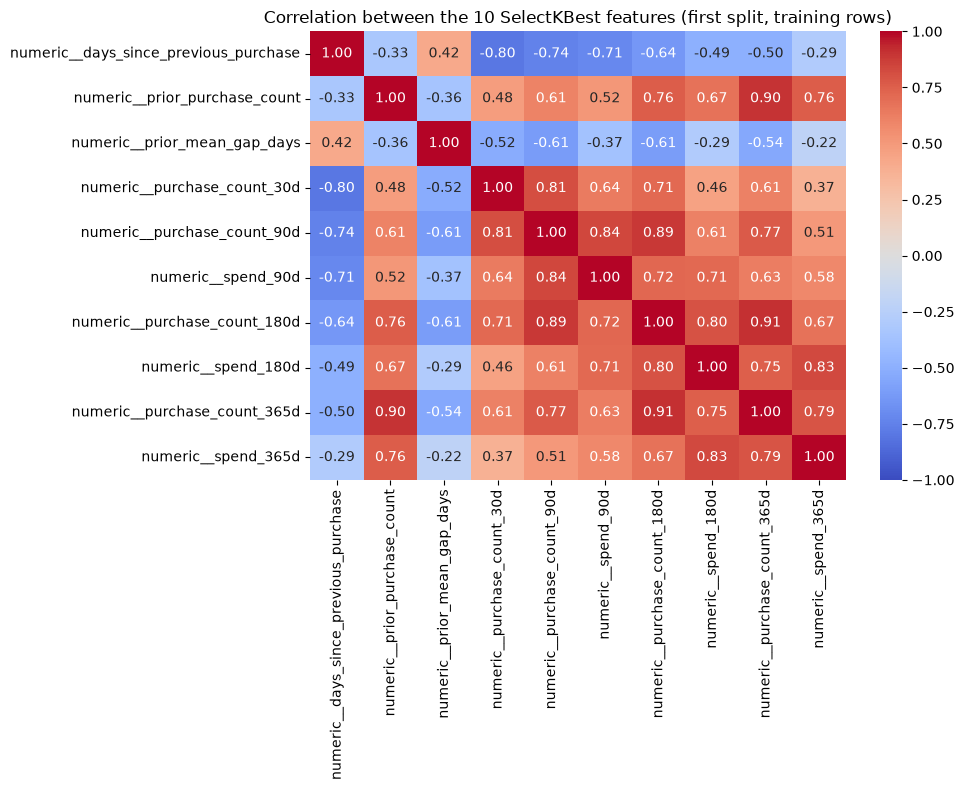

In [78]:
# Training rows of the first time split, prepared by Section 2
first_train_rows, _ = splits[0]
first_preprocessor = build_preprocessor()
first_matrix = first_preprocessor.fit_transform(X.iloc[first_train_rows])   # fitted on training rows only
first_names = first_preprocessor.named_steps["combine_columns"].get_feature_names_out()
first_y = y.iloc[first_train_rows]
first_frame = pd.DataFrame(first_matrix, columns=first_names)

# The 10 columns SelectKBest picks on these rows
top10 = first_names[SelectKBest(f_classif, k=10).fit(first_matrix, first_y).get_support()]

# Correlation between those 10 columns
correlation_matrix = first_frame[top10].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between the 10 SelectKBest features (first split, training rows)")
plt.tight_layout()
plt.show()

In [79]:
# Pairs of columns whose absolute correlation is above the threshold used in class
REDUNDANT = 0.70

corr_abs = correlation_matrix.abs()
# Keep only the upper triangle so each pair appears once
upper_triangle = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pairs = upper_triangle.stack().sort_values(ascending=False)

print(f"Pairs with correlation above {REDUNDANT}:")
print(pairs[pairs > REDUNDANT].round(2))

Pairs with correlation above 0.7:
numeric__purchase_count_180d           numeric__purchase_count_365d    0.91
numeric__prior_purchase_count          numeric__purchase_count_365d    0.90
numeric__purchase_count_90d            numeric__purchase_count_180d    0.89
                                       numeric__spend_90d              0.84
numeric__spend_180d                    numeric__spend_365d             0.83
numeric__purchase_count_30d            numeric__purchase_count_90d     0.81
numeric__purchase_count_180d           numeric__spend_180d             0.80
numeric__days_since_previous_purchase  numeric__purchase_count_30d     0.80
numeric__purchase_count_365d           numeric__spend_365d             0.79
numeric__purchase_count_90d            numeric__purchase_count_365d    0.77
numeric__prior_purchase_count          numeric__purchase_count_180d    0.76
                                       numeric__spend_365d             0.76
numeric__spend_180d                    numeric__purcha

Many pairs are above **0.70**. The strongest are:
- `purchase_count_180d` and `purchase_count_365d` (**0.91**);
- `prior_purchase_count` and `purchase_count_365d` (**0.90**);
- `purchase_count_90d` and `purchase_count_180d` (**0.89**).

This is expected: the rolling windows overlap (every purchase in the last 90 days is also in the last 180 and 365 days), and counts are strongly related to spend. So SelectKBest's top 10 contains **the same purchase-history information several times**.

### 3.6.2. Correlation filter (relevance + redundancy)

Instead of choosing by hand which correlated column to remove, we use the filter from class. It walks down the SelectKBest ranking (best score first) and **skips a column if its correlation with a column already kept is above 0.70**. Between two redundant columns, it automatically keeps the one with the higher score.

At the same budget (k = 10), the only difference from SelectKBest is the redundancy rule, so comparing the two shows what the rule is worth.

In [80]:
class CorrelationFilter:
    """Filter from class: go down the SelectKBest ranking and skip a column
    that is too correlated with a column already kept."""

    def __init__(self, k, redundancy=0.70):
        self.k = k                      # how many columns to keep
        self.redundancy = redundancy    # correlation above this = redundant

    def fit(self, matrix, target):
        matrix = np.asarray(matrix, dtype=float)
        with np.errstate(invalid="ignore", divide="ignore"):
            scores, _ = f_classif(matrix, target)                 # relevance: score of each column
            between = np.abs(np.corrcoef(matrix, rowvar=False))   # redundancy: correlation between columns
        # Constant columns give NaN; treat them as "no relation"
        scores, between = np.nan_to_num(scores), np.nan_to_num(between)

        keep = []
        for candidate in np.argsort(scores)[::-1]:               # best score first
            if len(keep) == self.k:                              # budget reached
                break
            if any(between[candidate, chosen] > self.redundancy for chosen in keep):
                continue                                         # too similar to a kept column: skip
            keep.append(candidate)

        self.support_ = np.zeros(matrix.shape[1], dtype=bool)   # True = column kept
        self.support_[keep] = True
        return self

    def get_support(self):
        return self.support_


corr_run = heldout_f1(select=lambda: CorrelationFilter(k=10, redundancy=REDUNDANT))
report("Correlation filter (k=10)", corr_run)

# Same budget as SelectKBest(k=10): the difference is the value of the redundancy rule
print("Against SelectKBest(k=10):", paired_delta(corr_run["F1"], kbest10_run["F1"]))
display(pd.DataFrame(results).T)

Correlation filter (k=10) -> {'columns': np.float64(10.0), 'F1': np.float64(0.7531), 'dF1': np.float64(0.0211), 'SEM': np.float64(0.0089), 'wins': '4/5', 'verdict': 'better'}
Kept in most splits: numeric__Total Desc_ Linha (5/5), numeric__prior_max_purchase_value (5/5), numeric__prior_mean_gap_days (5/5), categorical__payment_type_Maybe Tomorrow Payment 9 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 11 (5/5), numeric__prior_min_purchase_value (4/5), numeric__purchase_count_30d (4/5), numeric__spend_90d (4/5), numeric__purchase_count_365d (4/5), numeric__prior_std_gap_days_missing (4/5)
Against SelectKBest(k=10): {'dF1': np.float64(0.0128), 'SEM': np.float64(0.0061), 'wins': '4/5', 'verdict': 'better'}


,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise
TypedFilter (8 variables),78.4,0.738,0.006,0.0068,4/5,inside the noise
TypedFilter (15 variables),90.6,0.7348,0.0028,0.0072,3/5,inside the noise
Correlation filter (k=10),10.0,0.7531,0.0211,0.0089,4/5,better


**Results:** the correlation filter still keeps 10 columns, but more varied ones. Besides recent purchase behaviour (`purchase_count_30d`, `spend_90d`, `purchase_count_365d`), it keeps the time between purchases (`prior_mean_gap_days`), past purchase values (`prior_min_purchase_value`, `prior_max_purchase_value`), line discounts (`Total Desc_ Linha`), one payment type and one transport method.

With the same number of columns, it reaches **F1 ≈ 0.753 against 0.740** for SelectKBest(k=10) (*better*), and it is better than all features (0.732) on 4 of the 5 splits. **Removing redundancy helped**: ten different pieces of information are worth more than the same information repeated.

## 3.7. Wrapper method: Recursive Feature Elimination (RFE)

A wrapper method judges columns **through a fitted model**, so it can see effects that appear only when columns are used together (which a filter, scoring one column at a time, cannot see).

**How RFE works:** it trains a Logistic Regression, removes the columns with the smallest coefficients, trains again on the remaining columns, and repeats until only `k` columns are left. We use `step=10` (10 columns removed per round) to keep the running time reasonable.

**Choosing k.** Instead of fixing k in advance, we try **k = 5, 10, 15, 20, 30 and 40** and keep the k with the highest mean validation F1, as in class. Because the same validation splits are used to **choose** k and to **measure** it, this score is slightly optimistic, so we do not claim that RFE beats the reference.


In [81]:
# Try several numbers of columns and keep the best one (as in class)
candidate_k = [5, 10, 15, 20, 30, 40]
rfe_runs = {}   # one result table per k

for k in candidate_k:
    rfe_runs[k] = heldout_f1(select=lambda: RFE(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),  # model used to rank columns
        n_features_to_select=k,                                        # columns to keep
        step=10,                                                       # remove 10 columns per round
    ))
    print(f"k={k}: mean validation F1 = {rfe_runs[k]['F1'].mean():.4f}")

# Summary table: mean F1 and its standard error for each k
rfe_curve = pd.DataFrame({
    "k": candidate_k,
    "mean F1": [rfe_runs[k]["F1"].mean() for k in candidate_k],
    "SEM": [rfe_runs[k]["F1"].sem() for k in candidate_k],
})

# Best mean F1; if there is a tie, the smaller k wins (simpler model)
best_mean = rfe_curve["mean F1"].max()
chosen_k = int(rfe_curve.loc[rfe_curve["mean F1"] == best_mean, "k"].min())
print("Chosen k:", chosen_k)

k=5: mean validation F1 = 0.7288
k=10: mean validation F1 = 0.7420
k=15: mean validation F1 = 0.7386
k=20: mean validation F1 = 0.7451
k=30: mean validation F1 = 0.7376
k=40: mean validation F1 = 0.7377
Chosen k: 20


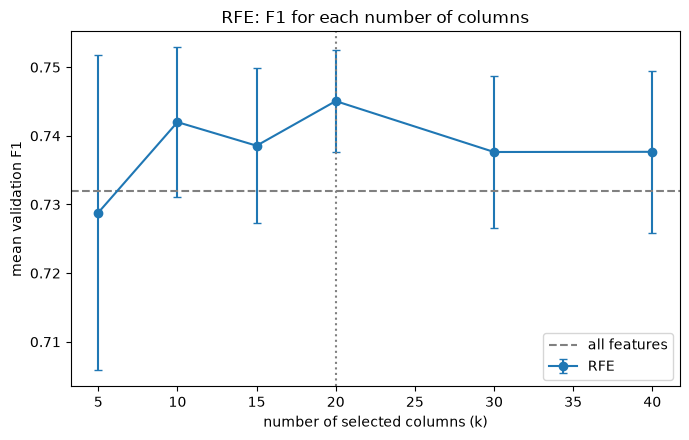

RFE (k chosen on validation) -> {'columns': np.float64(20.0), 'F1': np.float64(0.7451), 'dF1': np.float64(0.013), 'SEM': np.float64(0.0115), 'wins': '3/5', 'verdict': 'inside the noise'}
Kept in most splits: numeric__customer_tenure_days (5/5), numeric__prior_total_spend (5/5), numeric__purchase_count_365d (5/5), categorical__payment_type_Maybe Tomorrow Payment 9 (5/5), categorical__salesperson_VLOOKUP Master 8 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 11 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 18 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 2 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 22 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 68 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 9 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 48 (4/5), categorical__transport_method_Maybe Tomorrow Delivery 62 (4/5), categorical__transport_method_Maybe Tomorrow Delivery 51 (4/5), cate

,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise
TypedFilter (8 variables),78.4,0.738,0.006,0.0068,4/5,inside the noise
TypedFilter (15 variables),90.6,0.7348,0.0028,0.0072,3/5,inside the noise
Correlation filter (k=10),10.0,0.7531,0.0211,0.0089,4/5,better
RFE (k chosen on validation),20.0,0.7451,0.013,0.0115,3/5,inside the noise


In [82]:
# Plot the F1 for each k, with the all-features reference and the chosen k
plt.figure(figsize=(7, 4.5))
plt.errorbar(rfe_curve["k"], rfe_curve["mean F1"], yerr=rfe_curve["SEM"],
             marker="o", capsize=3, label="RFE")
plt.axhline(reference["F1"].mean(), color="grey", linestyle="--", label="all features")
plt.axvline(chosen_k, color="grey", linestyle=":")
plt.xlabel("number of selected columns (k)")
plt.ylabel("mean validation F1")
plt.title("RFE: F1 for each number of columns")
plt.legend()
plt.tight_layout()
plt.show()

# Only the chosen k goes into the results table
report("RFE (k chosen on validation)", rfe_runs[chosen_k])
display(pd.DataFrame(results).T)

**Results:** the best number of columns is **k = 20** (mean F1 ≈ 0.745, against 0.732 with all features). With 5 columns the model loses information, and 30 or 40 columns do not help.

RFE keeps a **different kind of set** from the filters. It keeps a few history columns (`customer_tenure_days`, `prior_total_spend`, `purchase_count_365d`) and many **single categories**, especially transport methods. This happens because RFE ranks columns by the size of the Logistic Regression coefficients, and rare categories can get large coefficients.

Since k was chosen on the same splits, we do not claim RFE is better than all features. We keep it as the **wrapper method** for the combinations in 3.9. Its preference for rare categories is examined in 3.9.2.

## 3.8. Embedded methods: L1 and Decision Tree

Embedded methods select columns **while the model is being fitted**. `SelectFromModel` fits a model, reads the weight or importance it gives each column, and keeps the columns above a threshold. As in class, we use two models:

- **L1 (Lasso) Logistic Regression.** The L1 penalty pushes the weights of weak columns to **exactly zero**. With `threshold=1e-8`, we keep the columns whose weight is not zero. `C=0.1` sets how strong the penalty is (smaller C = stronger penalty = fewer columns).
- **Decision tree importance.** A tree gives each column an *importance* (how much it helps split the data). The importances sum to 1. In class, `threshold="median"` was used to keep the more important half.

We do **not** use a Random Forest. In our first attempt, it selected `random_noise`: tree importances can favour columns with many different values even when those values carry no information.

In [83]:
# 1. L1 (Lasso) Logistic Regression: columns with weight exactly 0 are removed
l1_run = heldout_f1(select=lambda: SelectFromModel(
    LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,   # l1_ratio=1 means L1 penalty
                       max_iter=1000, random_state=RANDOM_STATE),
    threshold=1e-8))                                            # keep non-zero weights
report("L1 embedded", l1_run)

# 2. Decision tree importance with the median as the cut (as in class)
tree_median_run = heldout_f1(select=lambda: SelectFromModel(
    DecisionTreeClassifier(random_state=RANDOM_STATE), threshold="median"))
report("Tree importance (median)", tree_median_run)

L1 embedded -> {'columns': np.float64(33.0), 'F1': np.float64(0.7444), 'dF1': np.float64(0.0124), 'SEM': np.float64(0.0064), 'wins': '4/5', 'verdict': 'inside the noise'}
Tree importance (median) -> {'columns': np.float64(141.4), 'F1': np.float64(0.7324), 'dF1': np.float64(0.0004), 'SEM': np.float64(0.0004), 'wins': '1/5', 'verdict': 'inside the noise'}


L1 keeps about **33 columns** with F1 ≈ 0.744 (*inside the noise* compared with all features). The tree with the median, however, keeps about **141 columns**, almost all of them. We look at the importances to understand why.

In [84]:
# Tree importances on the training rows of the first split
tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(first_matrix, first_y)
importances = pd.Series(tree.feature_importances_, index=first_names)

print("Columns with importance exactly 0:", (importances == 0).sum(), "of", len(importances))
print("Median importance:", importances.median())
print("\nMost important columns:")
print(importances.sort_values(ascending=False).head(6).round(3))

Columns with importance exactly 0: 72 of 142
Median importance: 0.0

Most important columns:
numeric__purchase_count_365d     0.145
numeric__spend_180d              0.057
numeric__net_value_per_detail    0.051
numeric__Total Desc_ Linha       0.047
numeric__Custo                   0.044
numeric__spend_365d              0.043
dtype: float64


About **half of the columns have importance exactly 0**, so the **median is 0**. The rule "keep columns with importance ≥ median" then keeps every column, so it does not select anything on our data.

We therefore use the **mean** importance as the threshold, which keeps only the columns with above-average importance.

In [85]:
# Decision tree importance with the mean as the cut
tree_mean_run = heldout_f1(select=lambda: SelectFromModel(
    DecisionTreeClassifier(random_state=RANDOM_STATE), threshold="mean"))
report("Tree importance (mean)", tree_mean_run)

display(pd.DataFrame(results).T)

Tree importance (mean) -> {'columns': np.float64(25.8), 'F1': np.float64(0.7553), 'dF1': np.float64(0.0232), 'SEM': np.float64(0.005), 'wins': '5/5', 'verdict': 'better'}
Kept in most splits: numeric__Total a Pagar (5/5), numeric__Total Bruto (5/5), numeric__Total Liquido (5/5), numeric__Total Imp_ (5/5), numeric__Total Portes (5/5), numeric__Total Desc_ Linha (5/5), numeric__Custo (5/5), numeric__N_ Detalhes (5/5), numeric__days_since_previous_purchase (5/5), numeric__customer_tenure_days (5/5), numeric__prior_purchase_count (5/5), numeric__prior_total_spend (5/5), numeric__prior_mean_purchase_value (5/5), numeric__prior_std_purchase_value (5/5), numeric__prior_min_purchase_value (5/5), numeric__prior_max_purchase_value (5/5), numeric__prior_mean_gap_days (5/5), numeric__prior_std_gap_days (5/5), numeric__spend_30d (5/5), numeric__spend_90d (5/5), numeric__spend_180d (5/5), numeric__purchase_count_365d (5/5), numeric__spend_365d (5/5), numeric__net_value_per_detail (5/5)


,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise
TypedFilter (8 variables),78.4,0.738,0.006,0.0068,4/5,inside the noise
TypedFilter (15 variables),90.6,0.7348,0.0028,0.0072,3/5,inside the noise
Correlation filter (k=10),10.0,0.7531,0.0211,0.0089,4/5,better
RFE (k chosen on validation),20.0,0.7451,0.013,0.0115,3/5,inside the noise
L1 embedded,33.0,0.7444,0.0124,0.0064,4/5,inside the noise
Tree importance (median),141.4,0.7324,0.0004,0.0004,1/5,inside the noise


**Results:**
- **L1** keeps about 33 columns with F1 ≈ 0.744 (*inside the noise*). It keeps current purchase values (`Total Imp_`, `Custo`, `Total Desc_ Linha`, `net_value_per_detail`), customer history (`customer_tenure_days`, `prior_mean_gap_days`, `purchase_count_90d`, `purchase_count_365d`) and a few categories.
- The **tree with the median** (rule used in class) is ineffective at reducing the number of columns here, because the median importance is 0.
- The **tree with the mean** keeps about 26 columns with F1 ≈ 0.755, *better* than all features on all 5 splits. Its most important column is `purchase_count_365d`.

A rule from class is not automatically right for every dataset: here we had to check it and adapt it.

## 3.9. Combining strategies

Each family reads the columns in its own way: the filter looks at one column at a time, the wrapper (RFE) uses a fitted model, and the embedded method (L1) selects while the model learns. As in class, we combine **one method of each family**:

| Family | Method | Setting |
|---|---|---|
| Filter | Correlation filter | k = 35, redundancy 0.70 |
| Wrapper | RFE | k = 20 (chosen in 3.7) |
| Embedded | L1 Logistic Regression | C = 0.1 |

The filter uses k = 35 (as in class) so that it is not too strict when combined with the other two methods.

We combine them in two ways:
- **Sequence (funnel):** each method only sees the columns the previous one kept. One rejection is final.
- **Vote:** the three methods choose independently, and a column is kept when **at least 2 of the 3** choose it. One method alone cannot remove a column.

**Why combine?** In class, the combination was exported because the final model is not chosen yet, and a set that several methods agree on depends less on one method. We test whether this argument holds on our data: in 3.9.2 we compare the combinations with the single methods on several facts before choosing.

In [86]:
def shared_techniques():
    """One method per family, with the settings chosen above.
    A new, unfitted copy is created every time it is called."""
    return [
        ("filter", CorrelationFilter(k=35, redundancy=REDUNDANT)),
        ("wrapper", RFE(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                        n_features_to_select=chosen_k, step=10)),
        ("embedded", SelectFromModel(
            LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1,
                               max_iter=1000, random_state=RANDOM_STATE),
            threshold=1e-8)),
    ]


class Sequence:
    """Apply the methods one after another, each on the columns the previous one kept."""

    def __init__(self, stages):
        self.stages = stages

    def fit(self, matrix, target):
        matrix = np.asarray(matrix)
        support = np.ones(matrix.shape[1], dtype=bool)          # start with every column
        for name, stage in self.stages:
            # fit this stage only on the columns still kept
            kept = stage.fit(matrix[:, support], target).get_support()
            support[np.flatnonzero(support)] = kept             # update the kept columns
        self.support_ = support
        return self

    def get_support(self):
        return self.support_


class Vote:
    """Keep a column when at least `minimum` methods keep it."""

    def __init__(self, members, minimum=2):
        self.members = members
        self.minimum = minimum

    def fit(self, matrix, target):
        votes = np.zeros(np.asarray(matrix).shape[1], dtype=int)   # votes per column
        for name, member in self.members:
            votes += member.fit(matrix, target).get_support()      # +1 for each column this method keeps
        self.support_ = votes >= self.minimum                      # kept if enough votes
        return self

    def get_support(self):
        return self.support_

    def transform(self, matrix):
        """Keep only the selected columns (needed to use Vote inside a Pipeline in Section 4)."""
        return np.asarray(matrix)[:, self.support_]

In [87]:
# Test both combinations with the same splits and the same model
sequence_run = heldout_f1(select=lambda: Sequence(shared_techniques()))
report("Sequence: filter -> wrapper -> embedded", sequence_run)

vote_run = heldout_f1(select=lambda: Vote(shared_techniques(), minimum=2))
report("Vote: 2 of 3 methods", vote_run)

display(pd.DataFrame(results).T)

Sequence: filter -> wrapper -> embedded -> {'columns': np.float64(11.0), 'F1': np.float64(0.7398), 'dF1': np.float64(0.0078), 'SEM': np.float64(0.0065), 'wins': '3/5', 'verdict': 'inside the noise'}
Kept in most splits: numeric__prior_mean_gap_days (5/5), categorical__payment_type_Maybe Tomorrow Payment 9 (5/5), categorical__salesperson_VLOOKUP Master 4 (5/5), categorical__transport_method_Maybe Tomorrow Delivery 68 (5/5), numeric__Total Desc_ Linha (4/5), numeric__spend_90d (4/5), numeric__purchase_count_365d (4/5), categorical__transport_method_Maybe Tomorrow Delivery 51 (4/5), categorical__transport_method_Maybe Tomorrow Delivery 73 (4/5)
Vote: 2 of 3 methods -> {'columns': np.float64(24.4), 'F1': np.float64(0.7405), 'dF1': np.float64(0.0085), 'SEM': np.float64(0.007), 'wins': '3/5', 'verdict': 'inside the noise'}
Kept in most splits: numeric__Total Desc_ Linha (5/5), numeric__Custo (5/5), numeric__customer_tenure_days (5/5), numeric__prior_max_purchase_value (5/5), numeric__prior_m

,columns,F1,dF1,SEM,wins,verdict
all features,155.8,0.732,NaN,NaN,NaN,NaN
VarianceThreshold(0),134.8,0.7318,-0.0002,0.0002,0/5,inside the noise
SelectKBest(k=10),10.0,0.7403,0.0083,0.0066,4/5,inside the noise
SelectKBest(k=25),25.0,0.7533,0.0213,0.0123,3/5,inside the noise
TypedFilter (8 variables),78.4,0.738,0.006,0.0068,4/5,inside the noise
TypedFilter (15 variables),90.6,0.7348,0.0028,0.0072,3/5,inside the noise
Correlation filter (k=10),10.0,0.7531,0.0211,0.0089,4/5,better
RFE (k chosen on validation),20.0,0.7451,0.013,0.0115,3/5,inside the noise
L1 embedded,33.0,0.7444,0.0124,0.0064,4/5,inside the noise
Tree importance (median),141.4,0.7324,0.0004,0.0004,1/5,inside the noise


In [88]:
# Rule from class: compare the two combinations by their mean difference to all features
candidates = {
    "Sequence: filter -> wrapper -> embedded": sequence_run,
    "Vote: 2 of 3 methods": vote_run,
}
gaps = {name: (run["F1"] - reference["F1"]).mean() for name, run in candidates.items()}
best_combination = max(gaps, key=gaps.get)

for name, gap in gaps.items():
    print(f"{name}: mean difference to all features = {gap:+.4f}")
print("\nBetter combination (rule from class):", best_combination)
print("Difference between the two combinations:",
      paired_delta(vote_run["F1"], sequence_run["F1"]))

Sequence: filter -> wrapper -> embedded: mean difference to all features = +0.0078
Vote: 2 of 3 methods: mean difference to all features = +0.0085

Better combination (rule from class): Vote: 2 of 3 methods
Difference between the two combinations: {'dF1': np.float64(0.0007), 'SEM': np.float64(0.0056), 'wins': '3/5', 'verdict': 'inside the noise'}


**Results:** both combinations use far fewer columns than all features (about **11** and **24** instead of ~156) without losing F1: both differences are *inside the noise*. Following the rule used in class, the vote has the slightly higher mean (≈ 0.7405 against ≈ 0.7398), but the difference between the two combinations is itself *inside the noise*, so this rule cannot really separate them on our data.

- The **sequence** is stricter: a column rejected by the filter never reaches RFE or L1.
- The **vote** is more tolerant: one method alone cannot remove a column. Because RFE is one of its members, it also keeps several rare categories (see 3.9.2).

In class, the vote was exported because it was the only combination that did not lose F1. On our data, almost no method loses F1, so we do not choose automatically: in 3.9.2 we compare all candidates on further facts before deciding.

### 3.9.1. All methods compared

The figure shows, for every method, the mean difference in F1 compared with all features, with an error bar of 2 × SEM. A bar that crosses the dashed line at 0 means the method cannot be distinguished from using all features (*inside the noise*).

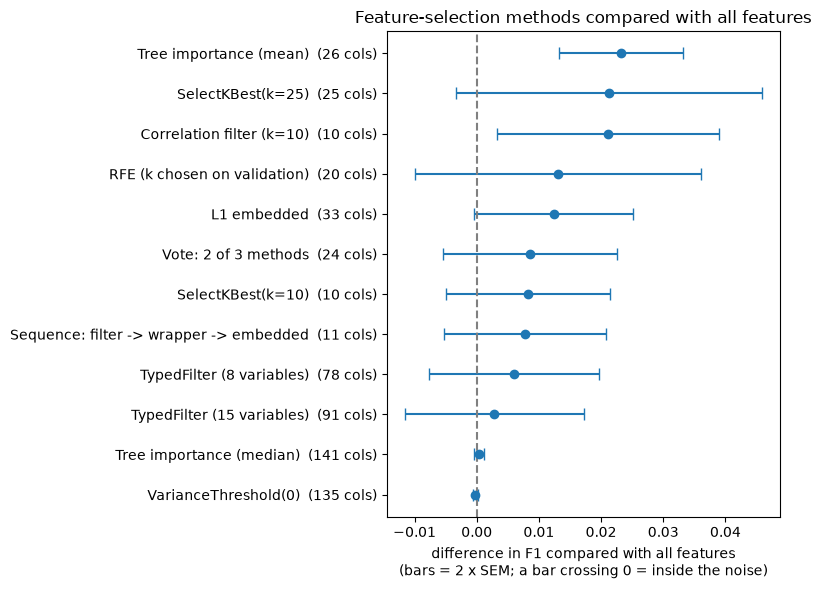

In [89]:
# ---------------------------------------------------------------
# All methods in one figure: difference to all features, with 2 x SEM
# ---------------------------------------------------------------
summary = pd.DataFrame(results).T.drop(index="all features")
summary = summary.astype({"dF1": float, "SEM": float, "columns": float})
summary = summary.sort_values("dF1")

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(summary["dF1"], np.arange(len(summary)), xerr=2 * summary["SEM"],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", linestyle="--")          # 0 = same F1 as all features
ax.set_yticks(np.arange(len(summary)))
ax.set_yticklabels([f"{name}  ({cols:.0f} cols)" for name, cols in zip(summary.index, summary["columns"])])
ax.set_xlabel("difference in F1 compared with all features\n(bars = 2 x SEM; a bar crossing 0 = inside the noise)")
ax.set_title("Feature-selection methods compared with all features")
fig.tight_layout()
plt.show()

**Reading the figure:**
- **No method is worse than all features**: every point is at or to the right of 0.
- Most bars **cross 0**: with only 5 time splits, most differences cannot be separated from noise. Only the decision tree with the mean threshold and the correlation filter (k=10) stay fully to the right of 0; L1 just touches 0.
- The bars of the different methods **overlap a lot**. On our data, F1 alone cannot clearly separate the methods from each other, so the choice of the final strategy also has to consider other facts: the number of columns, how stable the selected columns are across splits, and whether the selected columns make sense.

### 3.9.2. Choosing the final strategy

The figure shows that, on our data, **F1 alone cannot separate the methods**: their error bars overlap. So, instead of choosing the method with the highest number, we compare the candidates on three more facts, all measured on the same 5 splits:

- **columns**: how many columns the method keeps (fewer is simpler);
- **stability**: how similar the kept columns are from one split to another (mean Jaccard index between the 5 sets: 1 = always the same columns, 0 = completely different). A stable method gives a set we can trust and explain;
- **rare categories kept**: how many kept columns are categories used by **fewer than 20 different customers**. Such a column can work as a hidden customer identifier (see below).

In [90]:
# ---------------------------------------------------------------
# Criteria to choose the final strategy (beyond F1)
# ---------------------------------------------------------------
from itertools import combinations

# Number of different customers that use each category (train.csv only)
customers_per_category = {}
for column in categorical_columns:
    labels = X[column].astype("string").str.strip()
    customers_per_category[column] = X.assign(label=labels).groupby("label")["customer_id"].nunique()


def customers_of(name):
    """Number of customers using the category of a one-hot column (None for numeric columns)."""
    for column in categorical_columns:
        prefix = f"categorical__{column}_"
        if name.startswith(prefix):
            return customers_per_category[column].get(name[len(prefix):], 0)
    return None


def stability(run):
    """Mean overlap (Jaccard index) between the column sets kept in each pair of splits.
    1 = the same columns in every split, 0 = completely different columns."""
    sets = [set(kept) for kept in run["kept"]]
    return np.mean([len(a & b) / len(a | b) for a, b in combinations(sets, 2)])


def rare_categories(run, min_customers=20):
    """Average number of kept category columns used by fewer than `min_customers` customers."""
    counts = [sum(1 for c in kept if customers_of(c) is not None and customers_of(c) < min_customers)
              for kept in run["kept"]]
    return np.mean(counts)


candidate_runs = {
    "SelectKBest (k=25)": kbest25_run,
    "Correlation filter (k=10)": corr_run,
    f"RFE (k={chosen_k})": rfe_runs[chosen_k],
    "L1 embedded": l1_run,
    "Tree importance (mean)": tree_mean_run,
    "Sequence": sequence_run,
    "Vote": vote_run,
}

criteria = pd.DataFrame({
    name: {
        "columns": round(run["n"].mean(), 1),
        "F1": round(run["F1"].mean(), 4),
        "verdict vs all features": paired_delta(run["F1"], reference["F1"])["verdict"],
        "stability": round(stability(run), 2),
        "rare categories kept": round(rare_categories(run), 1),
    }
    for name, run in candidate_runs.items()
}).T
display(criteria)

,columns,F1,verdict vs all features,stability,rare categories kept
SelectKBest (k=25),25.0,0.7533,inside the noise,0.92,2.0
Correlation filter (k=10),10.0,0.7531,better,0.73,2.0
RFE (k=20),20.0,0.7451,inside the noise,0.6,13.6
L1 embedded,33.0,0.7444,inside the noise,0.69,1.2
Tree importance (mean),25.8,0.7553,better,0.88,0.2
Sequence,11.0,0.7398,inside the noise,0.52,1.4
Vote,24.4,0.7405,inside the noise,0.6,5.4


**Why rare categories matter.** RFE keeps on average about **14** columns of categories used by fewer than 20 customers, and the vote, which includes RFE, keeps about **5**. For example, transport method 11 has 253 purchases but only 2 customers. We check whether these customers come back because of the transport method or because of who they are:

In [91]:
# Example: transport method 11 (selected by RFE and by the correlation filter)
transport_labels = X["transport_method"].astype("string").str.strip()
uses_t11 = (transport_labels == "Maybe Tomorrow Delivery 11").fillna(False).to_numpy()

rows = []
for customer in X.loc[uses_t11, "customer_id"].unique():
    same_customer = (X["customer_id"] == customer).to_numpy()
    with_t11, without_t11 = same_customer & uses_t11, same_customer & ~uses_t11
    rows.append({
        "customer_id": customer,
        "purchases with transport 11": int(with_t11.sum()),
        "repeat rate with transport 11": round(y[with_t11].mean(), 2),
        "purchases with other transports": int(without_t11.sum()),
        "repeat rate with other transports": round(y[without_t11].mean(), 2) if without_t11.any() else np.nan,
    })
display(pd.DataFrame(rows))

,customer_id,purchases with transport 11,repeat rate with transport 11,purchases with other transports,repeat rate with other transports
0,103940,241,1.00,36,0.97
1,230585,12,0.67,1,0.00


241 of the 253 purchases with transport 11 come from **one customer**, who buys again **100%** of the times with transport 11 and **97%** of the times with other transport methods. The observed association with repeat purchase may be driven by customer identity rather than the transport method itself, since 241 out of 253 purchases using transport method 11 belong to the same customer.

**Decision.** We select **decision tree importance with the mean threshold** as our feature-selection strategy, because it is the best candidate on every fact we measured:
- it is one of only two methods *better* than all features (F1 ≈ 0.755), the other one being the correlation filter;
- it is very **stable** (0.88): it keeps almost the same columns in every split, while the vote (0.60), RFE (0.60) and the sequence (0.52) change a lot from split to split;
- it keeps almost **no rare categories** (0.2 on average), so it does not rely on hidden customer identifiers;
- its columns were judged with a Logistic Regression, so they also work for a linear model, not only for trees.

The correlation filter is a good simpler alternative (10 columns), but it is less stable (0.73) and keeps transport 11 in every split.

**Caveats.** The *mean* threshold was our own adaptation, chosen because the class rule (median) selected nothing on our data, not because of its F1. The method depends on a single model, and all F1 values are slightly optimistic because many methods were tested on the same 5 splits. Unlike the class example, we do not export the vote: on our data, the facts do not support it.

## 3.10. Testing identifier-like fields

The homework asks us to treat identifier-like fields **critically**. Section 2 removed `customer_id` (an identifier) and `random_noise` (a field of unknown meaning). Instead of accepting this blindly, we **add each one back** to all features and check whether the validation F1 changes.

`purchase_date` is not tested as a feature: it is used to build the time splits, the dates are anonymised, and a model that learns specific calendar days would not generalise to the later test period.

In [92]:
def heldout_f1_with_extra(extra_column):
    """Same as heldout_f1 with all features, plus one extra raw column."""
    rows = []
    for train_rows, validation_rows in splits:
        X_tr, X_va = X.iloc[train_rows], X.iloc[validation_rows]
        y_tr, y_va = y.iloc[train_rows], y.iloc[validation_rows]

        # Section 2 preprocessing, fitted on training rows only
        preprocessor = build_preprocessor()
        A_tr = preprocessor.fit_transform(X_tr)
        A_va = preprocessor.transform(X_va)

        # Fill and scale the extra column with TRAINING statistics only
        median = X_tr[extra_column].median()
        extra_tr = X_tr[extra_column].fillna(median)
        extra_va = X_va[extra_column].fillna(median)
        mean, std = extra_tr.mean(), extra_tr.std()
        A_tr = np.column_stack([A_tr, (extra_tr - mean) / std])   # add it as the last column
        A_va = np.column_stack([A_va, (extra_va - mean) / std])

        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(A_tr, y_tr)
        rows.append({"n": A_tr.shape[1], "F1": f1_score(y_va, model.predict(A_va))})
    return pd.DataFrame(rows)


# Compare "all features + extra column" with "all features"
for column in ["random_noise", "customer_id"]:
    run = heldout_f1_with_extra(column)
    print(f"Adding {column}:", paired_delta(run["F1"], reference["F1"]))

Adding random_noise: {'dF1': np.float64(0.0009), 'SEM': np.float64(0.0018), 'wins': '3/5', 'verdict': 'inside the noise'}
Adding customer_id: {'dF1': np.float64(0.001), 'SEM': np.float64(0.0029), 'wins': '2/5', 'verdict': 'inside the noise'}


**Results:** adding `random_noise` or `customer_id` does not change the F1 in a measurable way (about +0.0008 in both cases, *inside the noise*). They add no useful information, so we **confirm their removal**.

This matches the exploration in Section 1, where `random_noise` showed almost no relationship with the target. In our first attempt, the Random Forest still selected `random_noise`, which shows why importance scores alone should not be trusted.

## 3.11. Final feature set

We fit the selected strategy (**decision tree importance with the mean threshold**) on **all training rows** (including the rows without a date) to show the final set of columns. `test.csv` is not used.

In [93]:
# Prepare all training rows with the Section 2 preprocessing
final_preprocessor = build_preprocessor()
X_all_prepared = final_preprocessor.fit_transform(X)
all_names = final_preprocessor.named_steps["combine_columns"].get_feature_names_out()

# Fit the selected strategy on all training rows: tree importance, mean threshold
final_selector = SelectFromModel(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                 threshold="mean").fit(X_all_prepared, y)
final_features = list(all_names[final_selector.get_support()])

# Importance of each kept column (highest first)
final_importances = pd.Series(final_selector.estimator_.feature_importances_, index=all_names)
print(f"Final feature set: {len(final_features)} of {len(all_names)} columns "
      f"(importance threshold = mean = {final_selector.threshold_:.4f})\n")
display(final_importances[final_features].sort_values(ascending=False).round(3).to_frame("importance"))

Final feature set: 27 of 173 columns (importance threshold = mean = 0.0058)



,importance
numeric__purchase_count_365d,0.206
numeric__prior_mean_gap_days,0.057
numeric__net_value_per_detail,0.051
numeric__spend_365d,0.047
numeric__customer_tenure_days,0.040
numeric__Custo,0.039
numeric__N_ Detalhes,0.039
numeric__prior_std_gap_days,0.038
numeric__spend_180d,0.034
numeric__prior_total_spend,0.031


In [94]:
# Group the final columns by their original variable, to make the set easier to read
def source_variable(name):
    """numeric__spend_90d -> spend_90d ; categorical__payment_type_X -> payment_type"""
    if name.startswith("numeric__"):
        return name.replace("numeric__", "")
    for column in categorical_columns:
        if name.startswith(f"categorical__{column}_"):
            return column
    return name

final_by_source = pd.Series([source_variable(f) for f in final_features]).value_counts()
display(final_by_source.rename("columns kept").to_frame())

,columns kept
Total a Pagar,1
Total Bruto,1
Total Liquido,1
Total Imp_,1
Total Portes,1
Total Desc_ Linha,1
Custo,1
N_ Detalhes,1
days_since_previous_purchase,1
customer_tenure_days,1


The final set keeps **27 of 173 columns**: 26 numeric columns and one category.
- **Current purchase:** `Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Total Desc_ Linha`, `Custo`, `N_ Detalhes`, `net_value_per_detail`.
- **Customer history:** `days_since_previous_purchase`, `customer_tenure_days`, `prior_purchase_count`, `prior_total_spend`, `prior_mean/std/min/max_purchase_value`, `prior_mean_gap_days`, `prior_std_gap_days`.
- **Rolling activity:** `spend_30d`, `purchase_count_90d`, `spend_90d`, `purchase_count_180d`, `spend_180d`, `purchase_count_365d`, `spend_365d`.
- **Category:** `document_series` = Ctrl Z Series 2.

By far the most important column is **`purchase_count_365d`** (importance ≈ 0.21), followed by `prior_mean_gap_days` and `net_value_per_detail`. No transport method, salesperson or payment type is kept, so the set does not depend on rare categories that identify customers. The missing-value flags are not kept either.

Some kept columns are still correlated with each other (for example the three purchase totals, or spend over 90, 180 and 365 days). The tree keeps them because each one helps some of its splits, and this did not hurt the Logistic Regression in our comparison.

## 3.12. Conclusion

**Strategy.** We compared filter methods (VarianceThreshold, SelectKBest, relevance of the original variables with the TypedFilter, correlation filter), a wrapper method (RFE), embedded methods (L1 Logistic Regression and Decision Tree importance) and two combinations (sequence and vote). All of them were fitted only on the training rows of 5 time-based splits, built on the Section 2 preprocessing, and each was compared with the same model using all features.

**Summary of the results** (mean validation F1; reference = all features, F1 ≈ 0.732, ~156 columns):

| Method | Columns | F1 | Verdict vs all features | Stability |
|---|---|---|---|---|
| VarianceThreshold(0) | ~135 | ≈ 0.732 | same | – |
| SelectKBest (k=10) | 10 | ≈ 0.740 | inside the noise | – |
| SelectKBest (k=25) | 25 | ≈ 0.753 | inside the noise | 0.92 |
| TypedFilter (8 variables) | ~78 | ≈ 0.738 | inside the noise | – |
| Correlation filter (k=10) | 10 | ≈ 0.753 | better | 0.73 |
| RFE (k=20, chosen on validation) | 20 | ≈ 0.745 | inside the noise (optimistic) | 0.60 |
| L1 Logistic Regression | ~33 | ≈ 0.744 | inside the noise | 0.69 |
| Decision Tree (median) | ~141 | ≈ 0.732 | does not select (median = 0) | – |
| **Decision Tree (mean) — selected** | **~26** | **≈ 0.755** | **better** | **0.88** |
| Sequence | ~11 | ≈ 0.740 | inside the noise | 0.52 |
| Vote | ~24 | ≈ 0.741 | inside the noise | 0.60 |

**Main findings.**
- No selection method made the model worse: with far fewer columns, the F1 stayed the same or increased slightly.
- Many columns repeat the same purchase-history information (correlations up to 0.91), so removing redundancy helped.
- Some categories are used by only 1 or 2 customers and work as **hidden customer identifiers** (for example transport 11). RFE, and therefore the vote, keep many of them.
- `random_noise` and `customer_id` add no information and stay out (3.10).

**Selected strategy.** `SelectFromModel` with a **decision tree** and the **mean importance** as threshold. On our data it is the best candidate on every fact we measured: one of the two methods *better* than all features (F1 ≈ 0.755), the most stable apart from SelectKBest (0.88), and it keeps almost no rare categories. Unlike the class example, we do not export the vote: on our data, F1 does not support it over the other methods, and it is less stable and relies on rare categories. On all training data, the selected strategy keeps **27 of 173 columns** (see 3.11).

**Limitations.** Only 5 splits were used, so the standard errors are fairly large. The same validation splits were used to choose k, the threshold and the strategy, so these F1 values are slightly optimistic. The mean threshold is our adaptation of the class rule (the median was ineffective at reducing the number of columns on our data). `test.csv` was never used in this section.

**For Section 4.** We export the **strategy, not a fixed list of columns**: the selection is refitted inside the modelling pipeline, after the Section 2 preprocessing, so it only learns from training data:

    Pipeline([
        ("preprocess", build_preprocessor()),
        ("select", SelectFromModel(DecisionTreeClassifier(random_state=42), threshold="mean")),
        ("model", LogisticRegression(max_iter=1000)),   # or the model chosen in Section 4
    ])